<h1><center>CS 250: URL Prediction Model</center></h1>

# Import Libraries

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import streamlit as st


# Bring in Data and Get Basic Info

In [6]:
file = "PhiUSIIL_Phishing_URL_Dataset.csv"
data = pd.read_csv("PhiUSIIL_Phishing_URL_Dataset.csv")
data.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [8]:
data.describe()

,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
count,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,...,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000,235795.000000
mean,34.573095,21.470396,0.002706,78.430778,0.845508,0.260423,0.055747,2.764456,1.164758,0.002057,...,0.237007,0.023474,0.486775,26.075689,6.333111,10.522305,65.071113,2.377629,49.262516,0.571895
std,41.314153,9.150793,0.051946,28.976055,0.216632,0.251628,0.010587,0.599739,0.600969,0.045306,...,0.425247,0.151403,0.499826,79.411815,74.866296,22.312192,176.687539,17.641097,161.027430,0.494805
min,13.000000,4.000000,0.000000,0.155574,0.000000,0.000000,0.001083,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,23.000000,16.000000,0.000000,57.024793,0.680000,0.005977,0.050747,2.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,27.000000,20.000000,0.000000,100.000000,1.000000,0.079963,0.057970,3.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,8.000000,2.000000,6.000000,12.000000,0.000000,10.000000,1.000000
75%,34.000000,24.000000,0.000000,100.000000,1.000000,0.522907,0.062875,3.000000,1.000000,0.000000,...,0.000000,0.000000,1.000000,29.000000,8.000000,15.000000,88.000000,1.000000,57.000000,1.000000
max,6097.000000,110.000000,1.000000,100.000000,1.000000,0.522907,0.090824,13.000000,10.000000,1.000000,...,1.000000,1.000000,1.000000,8956.000000,35820.000000,6957.000000,27397.000000,4887.000000,27516.000000,1.000000


In [9]:
data.isnull().sum()

FILENAME                      0
URL                           0
URLLength                     0
Domain                        0
DomainLength                  0
IsDomainIP                    0
TLD                           0
URLSimilarityIndex            0
CharContinuationRate          0
TLDLegitimateProb             0
URLCharProb                   0
TLDLength                     0
NoOfSubDomain                 0
HasObfuscation                0
NoOfObfuscatedChar            0
ObfuscationRatio              0
NoOfLettersInURL              0
LetterRatioInURL              0
NoOfDegitsInURL               0
DegitRatioInURL               0
NoOfEqualsInURL               0
NoOfQMarkInURL                0
NoOfAmpersandInURL            0
NoOfOtherSpecialCharsInURL    0
SpacialCharRatioInURL         0
IsHTTPS                       0
LineOfCode                    0
LargestLineLength             0
HasTitle                      0
Title                         0
DomainTitleMatchScore         0
URLTitle

In [10]:
data['URL'].duplicated().sum()

np.int64(425)

In [11]:
data.nunique()

FILENAME                      235795
URL                           235370
URLLength                        482
Domain                        220086
DomainLength                     101
IsDomainIP                         2
TLD                              695
URLSimilarityIndex             36360
CharContinuationRate             898
TLDLegitimateProb                465
URLCharProb                   227421
TLDLength                         12
NoOfSubDomain                     10
HasObfuscation                     2
NoOfObfuscatedChar                20
ObfuscationRatio                 146
NoOfLettersInURL                 421
LetterRatioInURL                 709
NoOfDegitsInURL                  182
DegitRatioInURL                  575
NoOfEqualsInURL                   25
NoOfQMarkInURL                     5
NoOfAmpersandInURL                31
NoOfOtherSpecialCharsInURL        74
SpacialCharRatioInURL            240
IsHTTPS                            2
LineOfCode                     10738
L

# Clean the data

We will drop identifier, raw, highly correlated, and low variance columns that will impact the performance of our training 

In [12]:
data.iloc[:, -1].value_counts(normalize=True)

label
1    0.571895
0    0.428105
Name: proportion, dtype: float64

In [13]:
data = data.drop_duplicates(subset=['URL'], keep='first')

In [14]:
# Select only numeric columns from 'data'
numeric_data = data.select_dtypes(include=['int64', 'float64'])

# Get column names where variance is less than 0.01
low_variance_cols = numeric_data.columns[numeric_data.var() < 0.01].tolist()

print("Low variance columns to consider dropping:", low_variance_cols)

Low variance columns to consider dropping: ['IsDomainIP', 'URLCharProb', 'HasObfuscation', 'ObfuscationRatio', 'DegitRatioInURL', 'SpacialCharRatioInURL']


In [15]:
corr_matrix = data.select_dtypes(include=['int64', 'float64']).corr().abs()

# Find feature pairs with correlation greater than 0.90
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)]

print("Highly correlated features to consider dropping:", to_drop)

Highly correlated features to consider dropping: ['NoOfLettersInURL', 'URLTitleMatchScore']


In [16]:
cleaned_data= data.drop(['FILENAME', 'URL', 'Domain', 'TLD', 'Title','NoOfLettersInURL', 'URLTitleMatchScore'], axis=1)

cleaned_data.to_csv('cleaned_data.csv', index=False)

# Visualize and Explore The Data
The goal of these plots is to find patterns or correleation in the data through visual plots. Many of these features were suspected to be correlated so comparing them to the label column will give insight to important and relevant patterns.

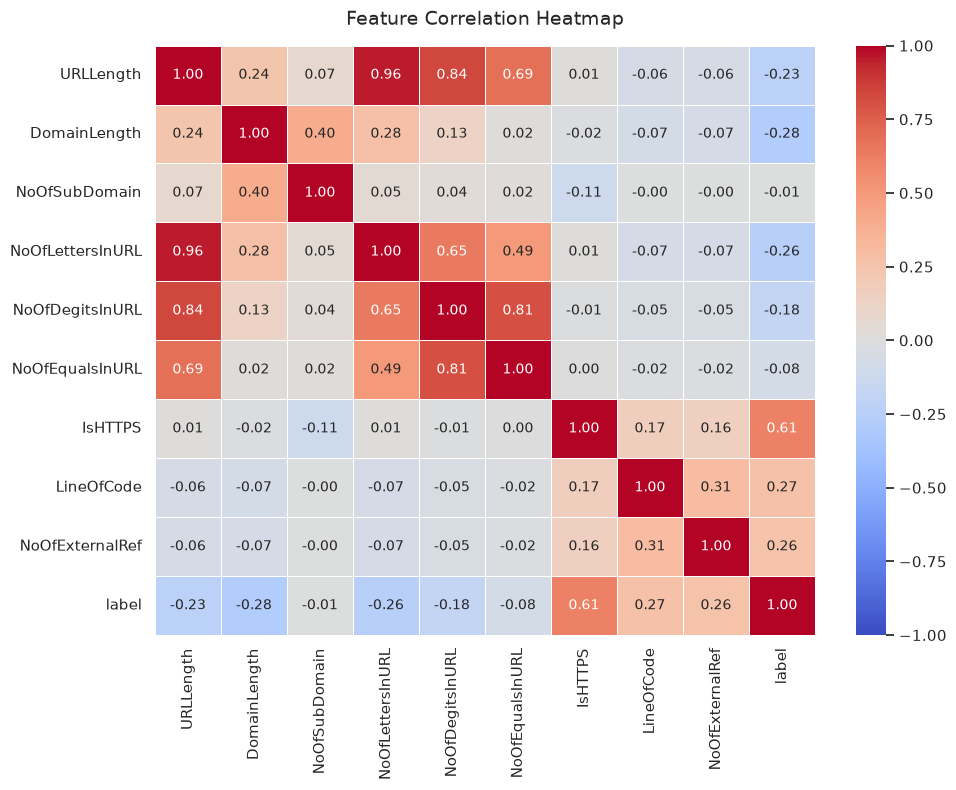

In [17]:
# --- Set global variables
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10})

# --- PLOT 1: Correlation Heatmap of Key Features ---
plt.figure(figsize=(10, 8))
key_features = [
    'URLLength', 'DomainLength', 'NoOfSubDomain', 'NoOfLettersInURL', 
    'NoOfDegitsInURL', 'NoOfEqualsInURL', 'IsHTTPS', 'LineOfCode', 
    'NoOfExternalRef', 'label']
corr = data[key_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, pad=15)
plt.tight_layout()
# plt.savefig('plot1_correlation_heatmap.png', dpi=300)
plt.show()

This plot reveals strong multicollinearity among character-count metrics and highlights linear relationships like IsHTTPS versus the target label. However, it leaves non-linear interactions entirely obscure since it only measures linear correlation coefficients.

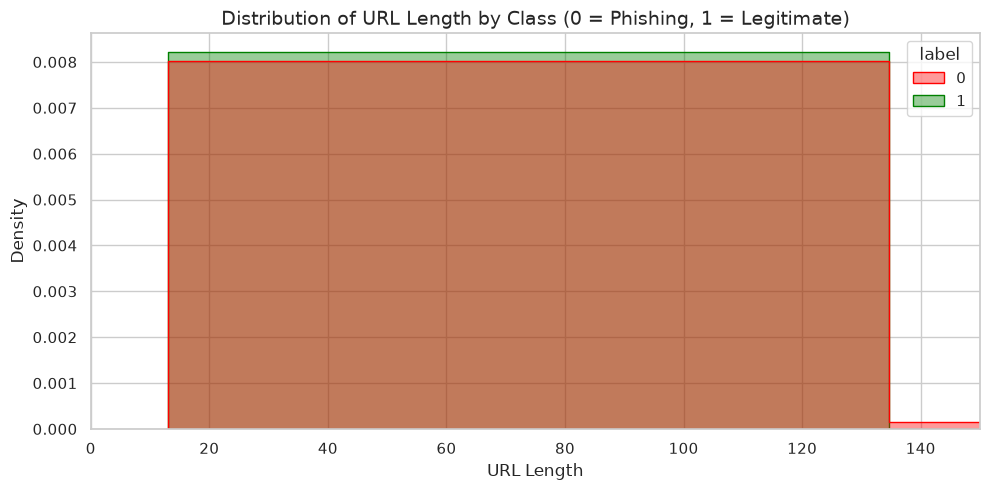

In [18]:
# --- PLOT 2: Distribution Comparison (URL Length by Label) ---
plt.figure(figsize=(10, 5))
sns.histplot(
    data=cleaned_data, x='URLLength', hue='label', 
    element='step', common_norm=False, stat='density', 
    palette=['red', 'green'], alpha=0.4, bins=50
)
plt.title('Distribution of URL Length by Class (0 = Phishing, 1 = Legitimate)', fontsize=14)
plt.xlabel('URL Length')
plt.ylabel('Density')
plt.xlim(0, 150) # Zoom in on the main cluster range
plt.tight_layout()
# plt.savefig('plot2_url_length_distribution.png', dpi=300)
plt.show()


This distribution reveals that phishing URLs often cluster differently in character length compared to legitimate sites. However, it leaves specific overlapping boundary ranges obscure where both classes share identical lengths.

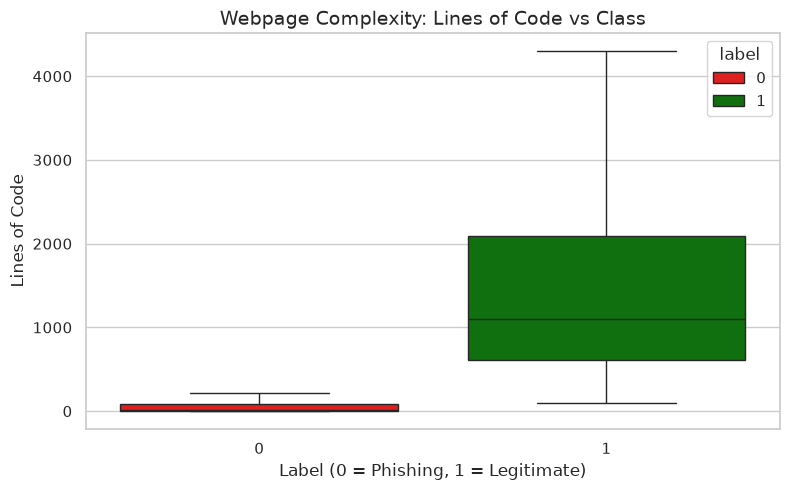

In [19]:
# --- PLOT 3: Box Plot of Webpage Complexity (Lines of Code vs. Label) ---
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=cleaned_data, x='label', y='LineOfCode', hue='label',
    palette=['red', 'green'], showfliers=False
)
plt.title('Webpage Complexity: Lines of Code vs Class', fontsize=14)
plt.xlabel('Label (0 = Phishing, 1 = Legitimate)')
plt.ylabel('Lines of Code')
plt.tight_layout()
# plt.savefig('plot3_lines_of_code_boxplot.png', dpi=300)
plt.show()

This plot highlights that legitimate web pages tend to contain significantly higher median lines of code due to structural and content richness.

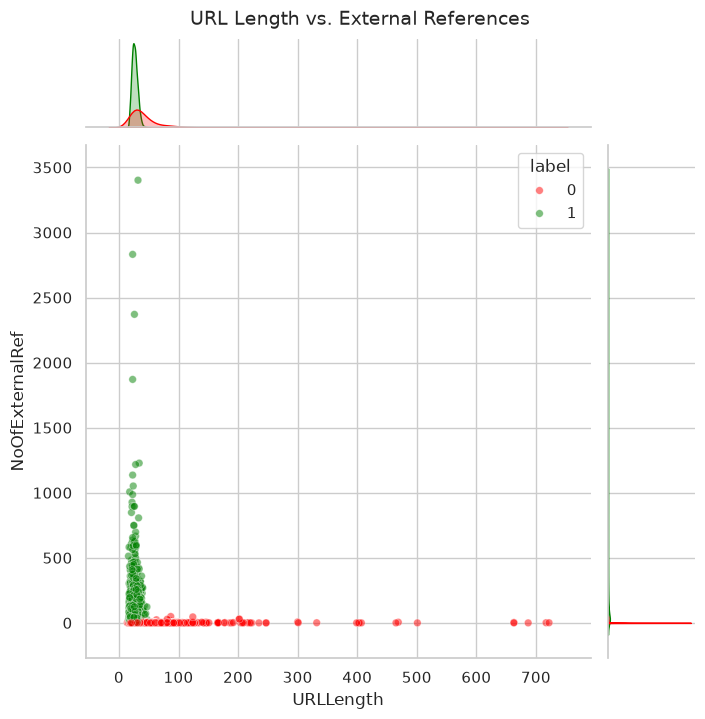

In [20]:
# --- PLOT 4: Scatter / Joint Plot (External References vs. URL Length) ---
g = sns.jointplot(
    data=cleaned_data.sample(5000, random_state=101), # Sample for clean rendering performance
    x='URLLength', y='NoOfExternalRef', 
    hue='label', palette=['red', 'green'], 
    alpha=0.5, height=7, s=30
)
g.fig.suptitle('URL Length vs. External References', y=1.02, fontsize=14)
# g.savefig('plot4_external_refs_vs_url_length.png', dpi=300)
plt.show()

This jointplot reveals dense clustering and correlation trends between URL length and external reference counts. 

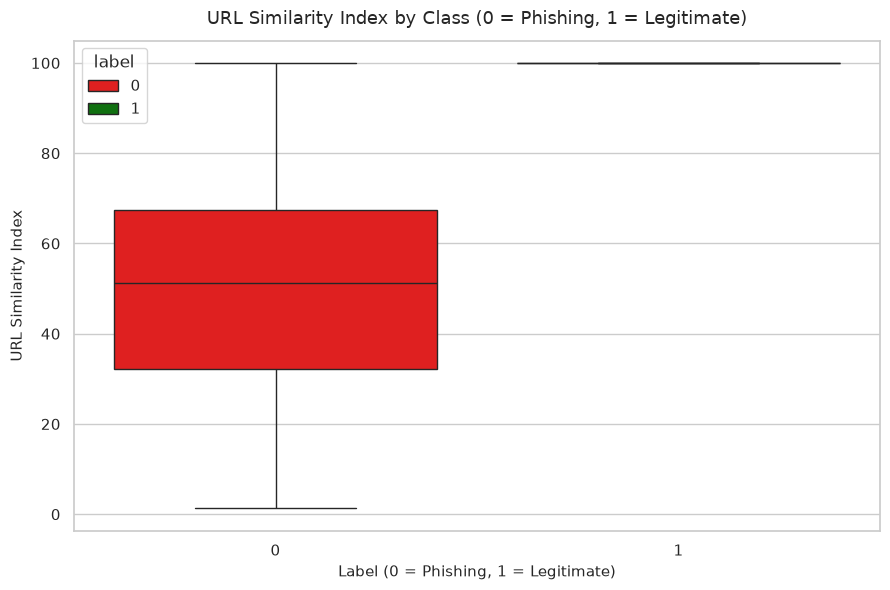

In [21]:
# --- PLOT 5: Box Plot of URL Similarity Index (Similarity index vs. Label) ---
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=cleaned_data.sample(10000, random_state=101), # sample for crisp rendering
    x='label', 
    y='URLSimilarityIndex',
    hue='label',
    palette=['red', 'green'],
    showfliers=True
)

plt.title('URL Similarity Index by Class (0 = Phishing, 1 = Legitimate)', fontsize=13, pad=12)
plt.xlabel('Label (0 = Phishing, 1 = Legitimate)', fontsize=11)
plt.ylabel('URL Similarity Index', fontsize=11)
plt.tight_layout()
# plt.savefig('plot5_url_similarity_boxplot.png', dpi=300)
plt.show()

This plot provides an obvious visual separation, showing that legitimate URLs consistently hit a maximum similarity score of 100 while phishing URLs spread widely toward zero. It leaves the specific mechanics of why individual phishing URLs receive intermediate similarity scores obscure.